Using device: cuda

Net(
  (model): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Dropout(p=0.25, inplace=False)
    (10): Linear(in_features=1568, out_features=10, bias=True)
  )
) 

Output shape of each layer (on a fake batch of 2 images):
  model.0                      Conv2d         -> (2, 16, 28, 28)
  model.1                      BatchNorm2d    -> (2, 16, 28, 28)
  model.2                      ReLU           -> (2, 16, 28, 28)
  model.3          

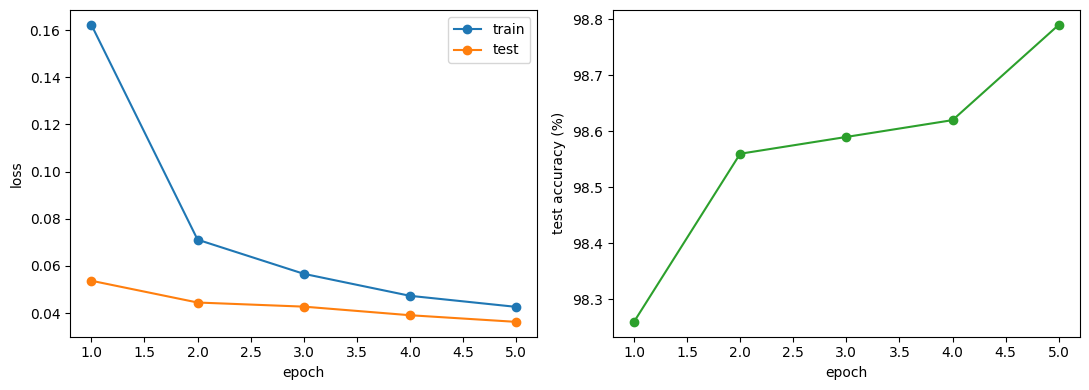

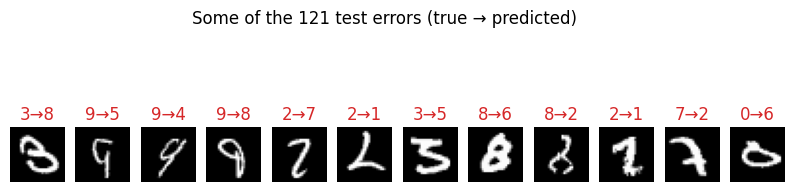

In [7]:
"""LAB 2 — Exercise: build your own CNN for MNIST.

Everything is ready: data loading, training loop, evaluation, plots and saving.
Your only job is to complete the TODOs in the `Net` class below, using the building
blocks shown in cnn_tools.ipynb (Conv2d, BatchNorm2d, ReLU, MaxPool2d, Dropout, ...).

Run it with:
    python cnn_mnist.py                      # default: 5 epochs, batch 64, lr 1e-3
    python cnn_mnist.py --epochs 3 --lr 5e-4

Goal: reach at least 98.5% test accuracy. Can you get above 99%?
"""
import argparse
import os
import sys
import time

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, "data")


# =============================================================================
# TODO: build your network
# =============================================================================
class Net(nn.Module):
    """Convolutional network for MNIST.

    Input:  a batch of images of shape (batch, 1, 28, 28)
    Output: a tensor of shape (batch, 10) with one score (logit) per digit.
            Do NOT apply softmax at the end: nn.CrossEntropyLoss does it for you.
    """

    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # block 1: 1 x 28 x 28 -> 16 x 14 x 14
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # block 2: 16 x 14 x 14 -> 32 x 7 x 7
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # classifier
            nn.Flatten(),
            nn.Dropout(0.25),
            nn.Linear(32 * 7 * 7, 10),
        )


    def forward(self, x):
        return self.model(x)


# =============================================================================
# From here on everything is ready: you don't need to modify anything
# (but read it, it's the same recipe as training.ipynb from Lab 1!)
# =============================================================================
def get_dataloaders(batch_size):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)),   # mean and std of the MNIST training set
    ])
    train_data = datasets.MNIST(root=DATA_DIR, train=True, download=True, transform=transform)
    test_data = datasets.MNIST(root=DATA_DIR, train=False, download=True, transform=transform)
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)
    return train_loader, test_loader


def check_model(net, device):
    """Print the output shape of every layer on a fake batch, and check the final output."""
    print("Output shape of each layer (on a fake batch of 2 images):")
    hooks = []
    for name, module in net.named_modules():
        if len(list(module.children())) == 0:      # only the "leaf" layers
            hooks.append(module.register_forward_hook(
                lambda m, inp, out, name=name: print(f"  {name:28s} {m.__class__.__name__:14s} -> {tuple(out.shape)}")
            ))
    net.eval()
    with torch.no_grad():
        out = net(torch.zeros(2, 1, 28, 28, device=device))
    for h in hooks:
        h.remove()

    if out.shape != (2, 10):
        raise ValueError(f"The network must return a tensor of shape (batch, 10), got {tuple(out.shape)}")
    n_params = sum(p.numel() for p in net.parameters())
    print(f"Total parameters: {n_params:,}\n")


def train_one_epoch(net, loader, loss_fn, optimizer, device):
    net.train()
    total_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        outputs = net(images)
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(net, loader, loss_fn, device):
    net.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            total_loss += loss_fn(outputs, labels).item()
            correct += (outputs.argmax(1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)


def plot_results(history, net, test_loader, device):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epochs, history["train_loss"], "o-", label="train")
    ax1.plot(epochs, history["test_loss"], "o-", label="test")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("loss")
    ax1.legend()
    ax2.plot(epochs, [100 * a for a in history["test_acc"]], "o-", color="tab:green")
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("test accuracy (%)")
    plt.tight_layout()
    plt.show()

    # Show some of the test images the network gets wrong
    net.eval()
    wrong_imgs, wrong_preds, wrong_labels = [], [], []
    with torch.no_grad():
        for images, labels in test_loader:
            preds = net(images.to(device)).argmax(1).cpu()
            mask = preds != labels
            wrong_imgs.append(images[mask])
            wrong_preds.append(preds[mask])
            wrong_labels.append(labels[mask])
    wrong_imgs = torch.cat(wrong_imgs)
    wrong_preds = torch.cat(wrong_preds)
    wrong_labels = torch.cat(wrong_labels)

    n = min(12, len(wrong_imgs))
    if n == 0:
        return
    fig = plt.figure(figsize=(10, 3))
    for i in range(n):
        ax = fig.add_subplot(1, n, i + 1)
        ax.imshow(wrong_imgs[i].squeeze(), cmap="gray")
        ax.set_title(f"{wrong_labels[i].item()}→{wrong_preds[i].item()}", color="tab:red")
        ax.axis("off")
    fig.suptitle(f"Some of the {len(wrong_imgs)} test errors (true → predicted)")
    plt.show()


def main(argv=None):
    parser = argparse.ArgumentParser()
    parser.add_argument("--epochs", type=int, default=5)
    parser.add_argument("--batch_size", type=int, default=64)
    parser.add_argument("--lr", type=float, default=1e-3)
    parser.add_argument("--no_plot", action="store_true", help="skip the final plots")
    args = parser.parse_args(argv)

    torch.manual_seed(0)
    if torch.cuda.is_available():
        device = "cuda"
    elif torch.backends.mps.is_available():
        device = "mps"
    else:
        device = "cpu"
    print(f"Using device: {device}\n")

    train_loader, test_loader = get_dataloaders(args.batch_size)

    net = Net().to(device)
    print(net, "\n")
    check_model(net, device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=args.lr)

    history = {"train_loss": [], "test_loss": [], "test_acc": []}
    for epoch in range(args.epochs):
        start = time.time()
        train_loss = train_one_epoch(net, train_loader, loss_fn, optimizer, device)
        test_loss, test_acc = evaluate(net, test_loader, loss_fn, device)
        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        print(f"Epoch [{epoch + 1}/{args.epochs}]  train loss: {train_loss:.4f}  "
              f"test loss: {test_loss:.4f}  test acc: {100 * test_acc:.2f}%  ({time.time() - start:.0f}s)")

    save_path = os.path.join(BASE_DIR, "mnist_cnn.pth")
    torch.save(net.state_dict(), save_path)
    print(f"\nModel saved to {save_path}")

    if not args.no_plot:
        plot_results(history, net, test_loader, device)


if __name__ == "__main__":
    main([] if "ipykernel" in sys.modules else None)
